# Intrusion Detection on UNSW-NB15: CNN vs LSTM vs CNN-LSTM

Corrected version of my thesis notebook. It trains three models on the same split and evaluates them on a held-out test set that keeps the original class ratio.

The journal version reported 99.99% accuracy because of data leakage. The README explains what leaked and what changed here.

# **Initialization**

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import glob as glob
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.utils import resample

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, Flatten, BatchNormalization, LeakyReLU
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Data Loading and Cleaning**

Both official CSV files are combined. The `id` column is dropped before removing duplicates, because a unique id on every row would make every row look distinct.

In [2]:
# 1. Data Loading and Preprocessing
path = "/content/drive/MyDrive/Colab Notebooks/Dataset/Training and Testing Sets" # use your path
files = [file for file in glob.glob(path + "**/*.csv", recursive=True)]

[print(f) for f in files]

data = [pd.read_csv(f) for f in files]

/content/drive/MyDrive/Colab Notebooks/Dataset/Training and Testing Sets/UNSW_NB15_testing-set.csv
/content/drive/MyDrive/Colab Notebooks/Dataset/Training and Testing Sets/UNSW_NB15_training-set.csv


In [3]:
# Remove duplicate data
data = pd.concat([d for d in data]).drop(columns=['id']).drop_duplicates(keep='first')
data.reset_index(drop=True, inplace = True)
data.shape

(162745, 44)

In [4]:
# Check dataset content and shape
data.shape
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162745 entries, 0 to 162744
Data columns (total 44 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   dur                162745 non-null  float64
 1   proto              162745 non-null  object 
 2   service            162745 non-null  object 
 3   state              162745 non-null  object 
 4   spkts              162745 non-null  int64  
 5   dpkts              162745 non-null  int64  
 6   sbytes             162745 non-null  int64  
 7   dbytes             162745 non-null  int64  
 8   rate               162745 non-null  float64
 9   sttl               162745 non-null  int64  
 10  dttl               162745 non-null  int64  
 11  sload              162745 non-null  float64
 12  dload              162745 non-null  float64
 13  sloss              162745 non-null  int64  
 14  dloss              162745 non-null  int64  
 15  sinpkt             162745 non-null  float64
 16  di

In [5]:
# Select all columns with "object" data type
obj_df = data.select_dtypes(include=['object']).copy()
obj_df.head()

,proto,service,state,attack_cat
0,udp,-,INT,Normal
1,udp,-,INT,Normal
2,udp,-,INT,Normal
3,udp,-,INT,Normal
4,udp,-,INT,Normal


In [6]:
# Encode categorical columns as integer codes
obj_df["proto"] = obj_df["proto"].astype('category')
obj_df["service"] = obj_df["service"].astype('category')
obj_df["state"] = obj_df["state"].astype('category')
obj_df["attack_cat"] = obj_df["attack_cat"].astype('category')
obj_df.dtypes

obj_df["proto_cat"] = obj_df["proto"].cat.codes
obj_df["service_cat"] = obj_df["service"].cat.codes
obj_df["state_cat"] = obj_df["state"].cat.codes
obj_df["attack_cat_cat"] = obj_df["attack_cat"].cat.codes

data["proto"]=obj_df["proto_cat"]
data["service"]=obj_df["service_cat"]
data["state"]=obj_df["state_cat"]
data["attack_cat"]=obj_df["attack_cat_cat"]

In [7]:
# Re-check dataset content & shape
data.groupby('label').agg({'label':'first', 'label':'count'}).rename_axis(None).sort_values('label', ascending=False)

,label
0,85722
1,77023


# **Split and Balancing**

The data is split into train, validation, and test sets first, stratified by label. Only the training set is upsampled, so no duplicated rows end up in validation or test. `attack_cat` is dropped because it gives the label away.

In [9]:
# Separate features and labels (ensure attack_cat is dropped to avoid target leakage)
X = data.drop(['label', 'attack_cat'], axis=1)
y = data['label']

# Split data into training and testing FIRST
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

# Data balancing using upsampling ONLY on training data
train_data = pd.concat([X_train, y_train], axis=1)
class_counts = train_data['label'].value_counts()
df_majority = train_data[train_data.label == class_counts.idxmax()]
df_minority = train_data[train_data.label == class_counts.idxmin()]
df_minority_upsampled = resample(df_minority, replace=True, n_samples=len(df_majority), random_state=42)
train_data_balanced = pd.concat([df_majority, df_minority_upsampled]).sample(frac=1, random_state=42)

X_train = train_data_balanced.drop('label', axis=1)
y_train = train_data_balanced['label']

# Normalize data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Define num_classes
num_classes = len(np.unique(y_train))

# One-hot encode labels
y_train = to_categorical(y_train, num_classes=num_classes)
y_val = to_categorical(y_val, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)


# **CNN Architecture**

Three Conv1D blocks with LeakyReLU, max pooling, and dropout, followed by two dense layers.

In [10]:
# 2. Build CNN Model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

def build_enhanced_model(input_shape, num_classes):
    model = Sequential(name="CNN")

    # CNN Block 1
    model.add(Conv1D(64, 3, input_shape=input_shape))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.3))

    # CNN Block 2
    model.add(Conv1D(64, 1))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.3))

    # CNN Block 3
    model.add(Conv1D(64, 1))
    model.add(LeakyReLU(alpha=0.1))
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.3))

    # Fully connected layers
    model.add(Flatten())
    model.add(Dense(64))
    model.add(LeakyReLU(alpha=0.1))
    model.add(Dense(32))
    model.add(LeakyReLU(alpha=0.1))

    # Output layer
    model.add(Dense(num_classes, activation='softmax'))

    return model

# Build model with appropriate input shape
input_shape = (X_train.shape[1], 1)
model = build_enhanced_model(input_shape, num_classes)

# Compile model with optimized learning rate
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy',
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

# Comprehensive callbacks
early_stopping = EarlyStopping(monitor='val_accuracy',
                              patience=15,
                              mode='max',
                              restore_best_weights=True,
                              verbose=1)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                factor=0.5,
                                                patience=5,
                                                min_lr=1e-6,
                                                verbose=1)

checkpoint = ModelCheckpoint('best_cnn.keras',
                           monitor='val_accuracy',
                           save_best_only=True,
                           mode='max')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


In [11]:
# 3. Train Model with Validation
history = model.fit(
    X_train, y_train,
    epochs=30,  # Increase number of epochs
    batch_size=64,  # Adjust batch size
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 24s 8ms/step - accuracy: 0.8430 - loss: 0.3249 - precision: 0.8430 - recall: 0.8430 - val_accuracy: 0.8759 - val_loss: 0.2532 - val_precision: 0.8759 - val_recall: 0.8759 - learning_rate: 5.0000e-04
Epoch 2/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8713 - loss: 0.2613 - precision: 0.8713 - recall: 0.8713 - val_accuracy: 0.8876 - val_loss: 0.2365 - val_precision: 0.8876 - val_recall: 0.8876 - learning_rate: 5.0000e-04
Epoch 3/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8797 - loss: 0.2446 - precision: 0.8797 - recall: 0.8797 - val_accuracy: 0.8906 - val_loss: 0.2222 - val_precision: 0.8906 - val_recall: 0.8906 - learning_rate: 5.0000e-04
Epoch 4/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8844 - loss: 0.2351 - precision: 0.8844 - recall: 0.8844 - val_accuracy: 0.8934 - val_loss: 0.2210 - val_precision: 0.8934 - val_recall: 0.8934 - learning_rate: 5.0000e-04
Epoch 5/30
1715/1715 ━━━━━━━━━━━━━━━━━

1018/1018 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Evaluation Metrics:
Accuracy: 0.9052
Precision: 0.9055
Recall: 0.9052
F1 Score: 0.9051


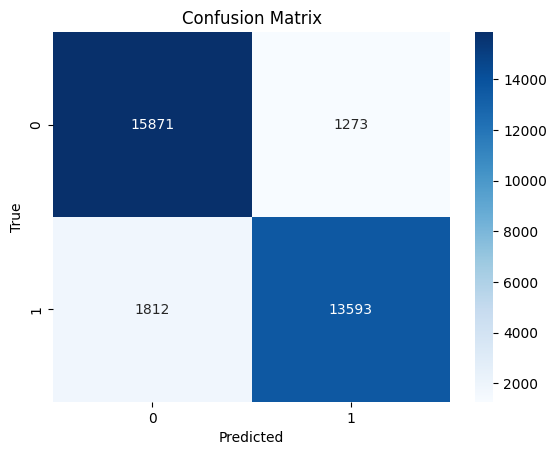

Classification Report:
              precision    recall  f1-score   support

      Benign     0.8975    0.9257    0.9114     17144
      Attack     0.9144    0.8824    0.8981     15405

    accuracy                         0.9052     32549
   macro avg     0.9059    0.9041    0.9048     32549
weighted avg     0.9055    0.9052    0.9051     32549



In [12]:
# 4. Model Evaluation
# Load best model weights
model.load_weights('best_cnn.keras')

# Predict on testing data
y_pred = model.predict(X_test)

# Get predicted labels
y_pred_labels = np.argmax(y_pred, axis=1)
# Get true labels for multiclass
y_true_labels = np.argmax(y_test, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true_labels, y_pred_labels)
precision = precision_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
recall = recall_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
f1 = f1_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass

print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=['Benign', 'Attack'], digits=4))

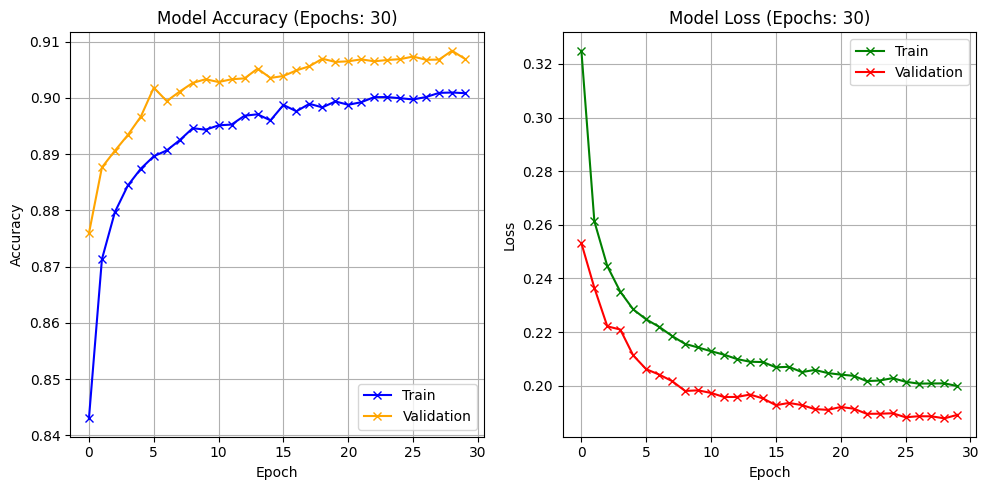

In [13]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Get the number of epochs from the history object
epochs = len(history.history['accuracy'])

# Plot accuracy
ax1.plot(history.history['accuracy'], label='Train', marker='x', linestyle='-', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation', marker='x', linestyle='-', color='orange')
ax1.set_title(f'Model Accuracy (Epochs: {epochs})')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Plot loss
ax2.plot(history.history['loss'], label='Train', marker='x', linestyle='-', color='green')
ax2.plot(history.history['val_loss'], label='Validation', marker='x', linestyle='-', color='red')
ax2.set_title(f'Model Loss (Epochs: {epochs})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# **LSTM Architecture**

Two stacked LSTM layers that read the 42 features as a sequence, followed by dense layers with batch normalization.

In [10]:
# 2. Build LSTM Model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

def build_enhanced_model(input_shape, num_classes):
    model = Sequential(name="LSTM")

    # Reshape input for LSTM
    model.add(tf.keras.layers.Reshape((input_shape[0], 1), input_shape=input_shape))

    # LSTM layers
    model.add(LSTM(128, return_sequences=True,
                 kernel_regularizer=l2(0.001)))
    model.add(Dropout(0.5))
    model.add(LSTM(64))
    model.add(Dropout(0.5))

    # Fully connected layers with regularization
    model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(Dropout(0.5))

    model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())

    # Output layer
    model.add(Dense(num_classes, activation='softmax'))

    return model

# Build model with appropriate input shape
input_shape = (X_train.shape[1],) # Correct input shape for reshape layer
model = build_enhanced_model(input_shape, num_classes)

# Compile model with optimized learning rate
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy',
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

# Comprehensive callbacks
early_stopping = EarlyStopping(monitor='val_accuracy',
                              patience=15,
                              mode='max',
                              restore_best_weights=True,
                              verbose=1)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                factor=0.5,
                                                patience=5,
                                                min_lr=1e-6,
                                                verbose=1)

checkpoint = ModelCheckpoint('best_lstm.keras',
                           monitor='val_accuracy',
                           save_best_only=True,
                           mode='max')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/reshape.py:38: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
# 3. Train Model with Validation
history = model.fit(
    X_train, y_train,
    epochs=30,  # Increase number of epochs
    batch_size=64,  # Adjust batch size
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 33s 14ms/step - accuracy: 0.7874 - loss: 0.5685 - precision: 0.7874 - recall: 0.7874 - val_accuracy: 0.8472 - val_loss: 0.4091 - val_precision: 0.8472 - val_recall: 0.8472 - learning_rate: 5.0000e-04
Epoch 2/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.8486 - loss: 0.3903 - precision: 0.8486 - recall: 0.8486 - val_accuracy: 0.8498 - val_loss: 0.3366 - val_precision: 0.8498 - val_recall: 0.8498 - learning_rate: 5.0000e-04
Epoch 3/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - accuracy: 0.8547 - loss: 0.3259 - precision: 0.8547 - recall: 0.8547 - val_accuracy: 0.8587 - val_loss: 0.2879 - val_precision: 0.8587 - val_recall: 0.8587 - learning_rate: 5.0000e-04
Epoch 4/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.8584 - loss: 0.2897 - precision: 0.8584 - recall: 0.8584 - val_accuracy: 0.8705 - val_loss: 0.2595 - val_precision: 0.8705 - val_recall: 0.8705 - learning_rate: 5.0000e-04
Epoch 5/30
1715/1715 ━━━━━━━━━━━

1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
Evaluation Metrics:
Accuracy: 0.9019
Precision: 0.9020
Recall: 0.9019
F1 Score: 0.9019


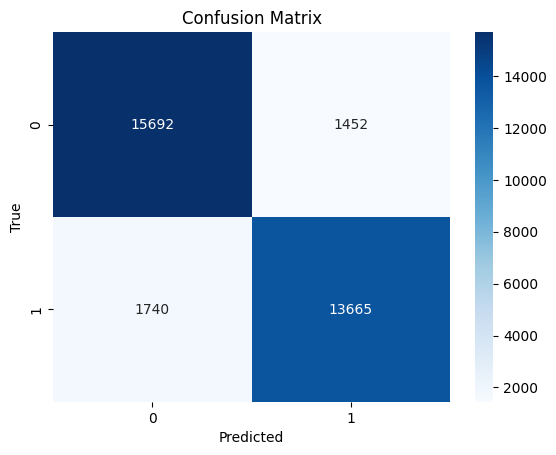

Classification Report:
              precision    recall  f1-score   support

      Benign       0.90      0.92      0.91     17144
      Attack       0.90      0.89      0.90     15405

    accuracy                           0.90     32549
   macro avg       0.90      0.90      0.90     32549
weighted avg       0.90      0.90      0.90     32549



In [12]:
# 4. Model Evaluation
# Load best model weights
model.load_weights('best_lstm.keras')

# Predict on testing data
y_pred = model.predict(X_test)

# Get predicted labels
y_pred_labels = np.argmax(y_pred, axis=1)
# Get true labels for multiclass
y_true_labels = np.argmax(y_test, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true_labels, y_pred_labels)
precision = precision_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
recall = recall_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
f1 = f1_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass

print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=['Benign', 'Attack'], digits=4))

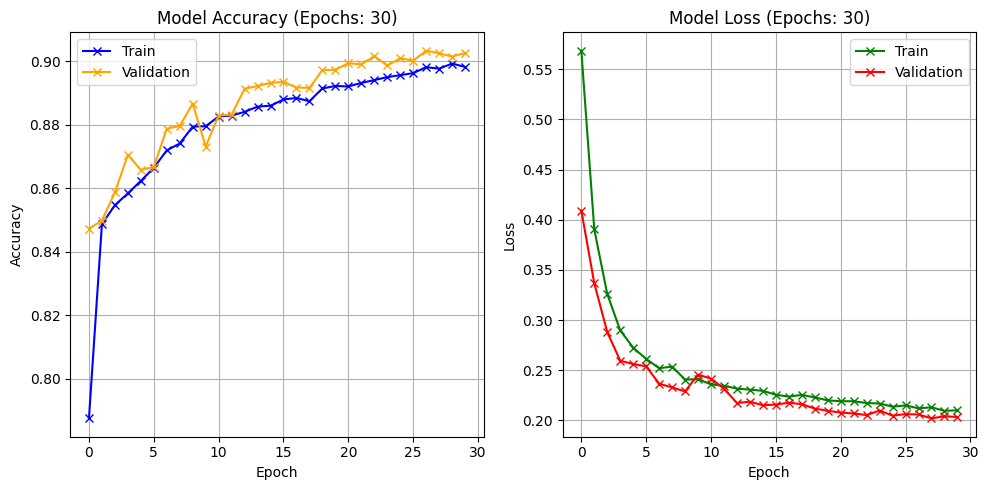

In [13]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Get the number of epochs from the history object
epochs = len(history.history['accuracy'])

# Plot accuracy
ax1.plot(history.history['accuracy'], label='Train', marker='x', linestyle='-', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation', marker='x', linestyle='-', color='orange')
ax1.set_title(f'Model Accuracy (Epochs: {epochs})')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Plot loss
ax2.plot(history.history['loss'], label='Train', marker='x', linestyle='-', color='green')
ax2.plot(history.history['val_loss'], label='Validation', marker='x', linestyle='-', color='red')
ax2.set_title(f'Model Loss (Epochs: {epochs})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# **CNN-LSTM Architecture**

Three Conv1D blocks pick up local patterns between neighbouring features, then the same LSTM and dense stack as the LSTM model.

In [10]:
# 2. Build CNN-LSTM Model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

def build_enhanced_model(input_shape, num_classes):
    model = Sequential(name="CNN_LSTM")

    # CNN Block 1
    model.add(Conv1D(filters=128, kernel_size=3, activation='relu',
                    input_shape=input_shape,
                    kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.4))

    # CNN Block 2
    model.add(Conv1D(filters=128, kernel_size=2, activation='relu',
                    kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.4))

    # CNN Block 3
    model.add(Conv1D(filters=64, kernel_size=1, activation='relu',
                    kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))

    # LSTM layers
    model.add(LSTM(128, return_sequences=True,
                 kernel_regularizer=l2(0.001)))
    model.add(Dropout(0.5))
    model.add(LSTM(64))
    model.add(Dropout(0.5))

    # Fully connected layers with regularization
    model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())
    model.add(Dropout(0.5))

    model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(BatchNormalization())

    # Output layer
    model.add(Dense(num_classes, activation='softmax'))

    return model

# Build model with appropriate input shape
input_shape = (X_train.shape[1], 1)
model = build_enhanced_model(input_shape, num_classes)

# Compile model with optimized learning rate
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy',
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

# Comprehensive callbacks
early_stopping = EarlyStopping(monitor='val_accuracy',
                              patience=15,
                              mode='max',
                              restore_best_weights=True,
                              verbose=1)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                factor=0.5,
                                                patience=5,
                                                min_lr=1e-6,
                                                verbose=1)

checkpoint = ModelCheckpoint('best_cnn_lstm.keras',
                           monitor='val_accuracy',
                           save_best_only=True,
                           mode='max')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
# 3. Train Model with Validation
history = model.fit(
    X_train, y_train,
    epochs=30,  # Increase number of epochs
    batch_size=64,  # Adjust batch size
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 38s 16ms/step - accuracy: 0.8187 - loss: 0.8036 - precision: 0.8187 - recall: 0.8187 - val_accuracy: 0.8590 - val_loss: 0.5714 - val_precision: 0.8590 - val_recall: 0.8590 - learning_rate: 5.0000e-04
Epoch 2/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 28s 17ms/step - accuracy: 0.8593 - loss: 0.4941 - precision: 0.8593 - recall: 0.8593 - val_accuracy: 0.8832 - val_loss: 0.3791 - val_precision: 0.8832 - val_recall: 0.8832 - learning_rate: 5.0000e-04
Epoch 3/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.8719 - loss: 0.3513 - precision: 0.8719 - recall: 0.8719 - val_accuracy: 0.8893 - val_loss: 0.2934 - val_precision: 0.8893 - val_recall: 0.8893 - learning_rate: 5.0000e-04
Epoch 4/30
1715/1715 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.8780 - loss: 0.2961 - precision: 0.8780 - recall: 0.8780 - val_accuracy: 0.8980 - val_loss: 0.2560 - val_precision: 0.8980 - val_recall: 0.8980 - learning_rate: 5.0000e-04
Epoch 5/30
1715/1715 ━━━━━━━━━━━

1018/1018 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step
Evaluation Metrics:
Accuracy: 0.9047
Precision: 0.9050
Recall: 0.9047
F1 Score: 0.9046


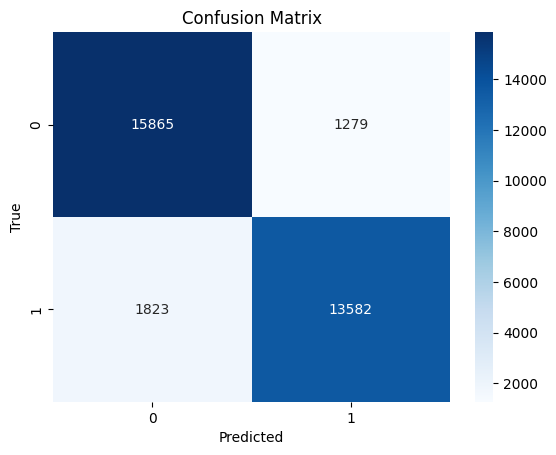

Classification Report:
              precision    recall  f1-score   support

      Benign     0.8969    0.9254    0.9109     17144
      Attack     0.9139    0.8817    0.8975     15405

    accuracy                         0.9047     32549
   macro avg     0.9054    0.9035    0.9042     32549
weighted avg     0.9050    0.9047    0.9046     32549



In [12]:
# 4. Model Evaluation
# Load best model weights
model.load_weights('best_cnn_lstm.keras')

# Predict on testing data
y_pred = model.predict(X_test)

# Get predicted labels
y_pred_labels = np.argmax(y_pred, axis=1)
# Get true labels for multiclass
y_true_labels = np.argmax(y_test, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true_labels, y_pred_labels)
precision = precision_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
recall = recall_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass
f1 = f1_score(y_true_labels, y_pred_labels, average='weighted')  # Use 'weighted' for multiclass

print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=['Benign', 'Attack'], digits=4))

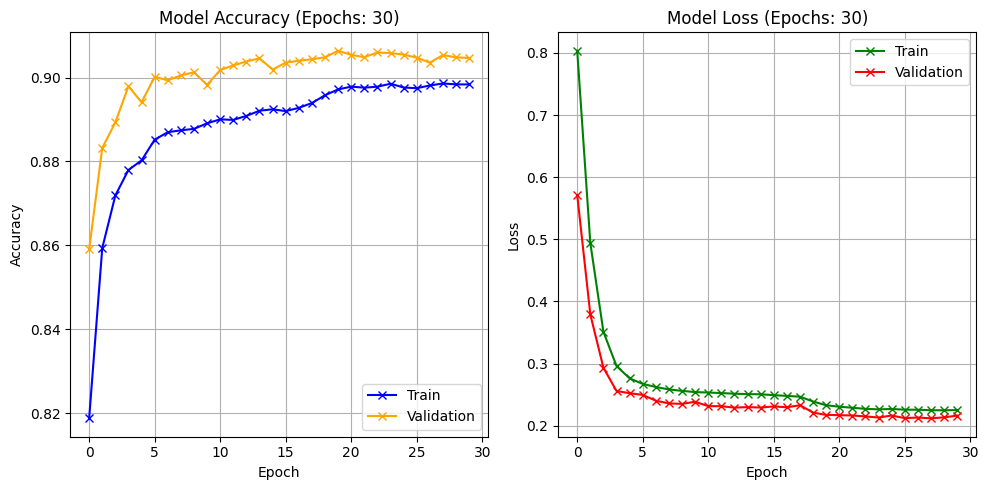

In [13]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Get the number of epochs from the history object
epochs = len(history.history['accuracy'])

# Plot accuracy
ax1.plot(history.history['accuracy'], label='Train', marker='x', linestyle='-', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation', marker='x', linestyle='-', color='orange')
ax1.set_title(f'Model Accuracy (Epochs: {epochs})')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Plot loss
ax2.plot(history.history['loss'], label='Train', marker='x', linestyle='-', color='green')
ax2.plot(history.history['val_loss'], label='Validation', marker='x', linestyle='-', color='red')
ax2.set_title(f'Model Loss (Epochs: {epochs})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()